In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm

In [4]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.1,0.1],[0.1,0.8,0.1],[0.1,0.1,0.8]])
bandwidth = 1/3
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,bandwidth)

In [5]:
#original integral and normalised one
print(graphon.integral(graphon_matrix), graphon.integral())

0.33333333333333337 1.0


In [6]:
#new graphon after normalisation
graphon.graphon

array([[2.4, 0.3, 0.3],
       [0.3, 2.4, 0.3],
       [0.3, 0.3, 2.4]])

In [7]:
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt

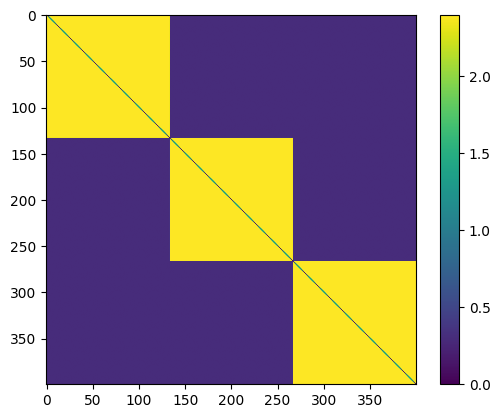

In [8]:
plt.imshow(graphon._get_edge_probabilities(400,False,True))
plt.colorbar()
plt.show()

In [9]:
#Draw a graph from the graphon with a given density and number of vertices, see GraphonAbstract.py
n=300
rho_n=0.3
A = graphon.draw(rho = rho_n,n = n, exchangeable=False)

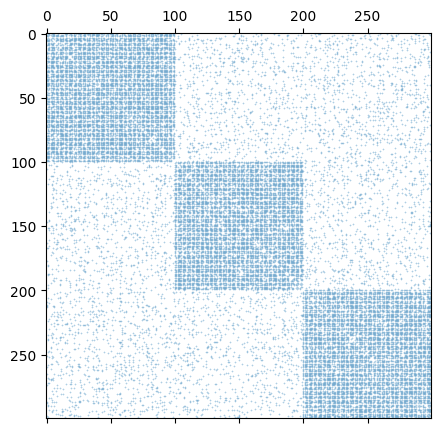

In [10]:
fig, ax = spy(A)#from pygraphon.plots.plot_matrices
plt.show()

In [11]:
edge_density(A)

0.29741360089186175

In [12]:
from pygraphon.estimators.HistogramEstimator import HistogramEstimator
from pygraphon.estimators.MomentEstimator import MomentEstimator, SimpleMomentEstimator

In [24]:
hist = HistogramEstimator()
hist_epprox = hist.estimate(adjacency_matrix= A, bandwidthHist= None)
P = hist.estimated_edge_connectivity_matrix

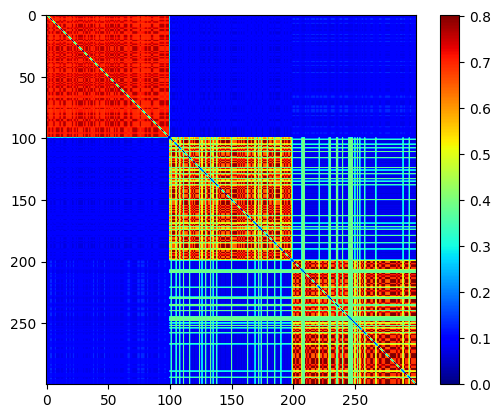

In [28]:
plt.imshow(P, cmap = "jet")
plt.colorbar()
plt.show()

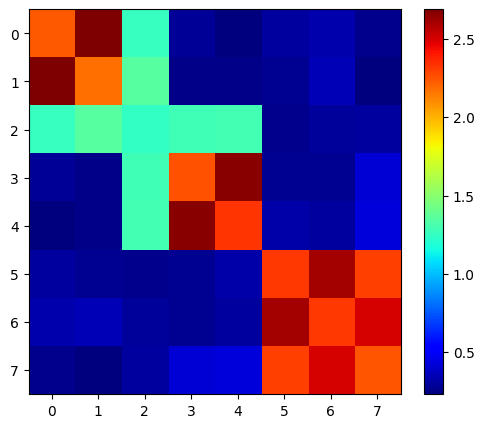

In [14]:
from pygraphon.plots.plots_graphon import plot
plot(hist_epprox)
plt.show()

In [15]:
from pygraphon.subgraph_isomorphism.CycleCount import CycleCount
counter = CycleCount(L = 9)

In [16]:
momentestimator = SimpleMomentEstimator(3)
mome_simple_approx = momentestimator.estimate(adjacency_matrix= A)

c:\Users\verdeyme\Desktop\Code\pygraphon\env\lib\site-packages\scipy\optimize\_minpack_py.py:175: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last five Jacobian evaluations.
  warnings.warn(msg, RuntimeWarning)


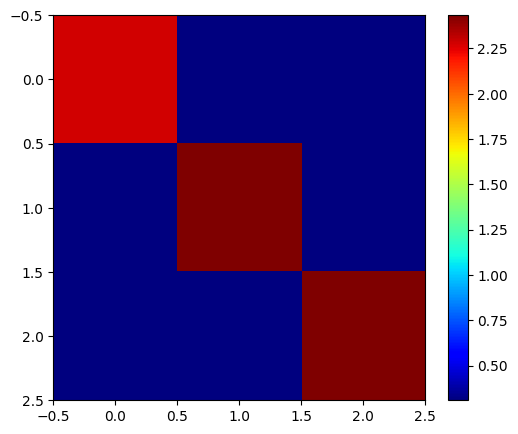

In [17]:
plot(mome_simple_approx)
plt.show()

In [18]:
mome_simple_approx.graphon

array([[2.28304365, 0.30957033, 0.30957033],
       [0.30957033, 2.42644962, 0.30957033],
       [0.30957033, 0.30957033, 2.43308475]])

In [19]:
mome_simple_approx.integral()

1.0

Clustering the tiles independently (i.e. without structure)

In [20]:
from sklearn.cluster import KMeans
#Extract tiles and reshape
nrow_tile = hist_epprox.graphon.shape[0]
flat_graphon = hist_epprox.graphon[np.triu_indices(nrow_tile)]
#Clustering according to kmeans
max_k = int(nrow_tile*(nrow_tile+1)/2)#number of individual tile
avr_graphon = np.asarray([flat_graphon.copy() for k in range(max_k)])#copies for different number of clusters
for i in range(max_k-1):
    if i==0:
        avr_graphon[i]=edge_density(A)*np.ones_like(flat_graphon)
    else:
        kmeans = KMeans(n_clusters=i+1, random_state=0).fit(flat_graphon.reshape(-1,1))
        #Smooth using mean by memberhsip
        for j in range(i+1):#average tiles of same community
            avr_graphon[i][kmeans.labels_==j] = flat_graphon[kmeans.labels_==j].mean()

C:\Users\verdeyme\AppData\Local\Temp\ipykernel_19536\1140700371.py:12: ConvergenceWarning: Number of distinct clusters (32) found smaller than n_clusters (33). Possibly due to duplicate points in X.
  kmeans = KMeans(n_clusters=i+1, random_state=0).fit(flat_graphon.reshape(-1,1))
C:\Users\verdeyme\AppData\Local\Temp\ipykernel_19536\1140700371.py:15: RuntimeWarning: Mean of empty slice.
  avr_graphon[i][kmeans.labels_==j] = flat_graphon[kmeans.labels_==j].mean()
c:\Users\verdeyme\Desktop\Code\pygraphon\env\lib\site-packages\numpy\core\_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
C:\Users\verdeyme\AppData\Local\Temp\ipykernel_19536\1140700371.py:12: ConvergenceWarning: Number of distinct clusters (32) found smaller than n_clusters (34). Possibly due to duplicate points in X.
  kmeans = KMeans(n_clusters=i+1, random_state=0).fit(flat_graphon.reshape(-1,1))
C:\Users\verdeyme\AppData\Local\Temp\ipykernel_19536\1140700371.p

In [21]:
#Reverse flattening back to 2d
KM_smooth_graphon = np.zeros((max_k,nrow_tile, nrow_tile))#initiate matrix containing smooth graphon
i,j = np.triu_indices(nrow_tile)
KM_smooth_graphon[:,i,j]=avr_graphon

In [22]:
#Make it symmetric by extracting diag, making it 3d and doing X+X^T-diag(X)
#Extract diagonal
i,j=np.diag_indices(nrow_tile)
diag_KM_vec=np.diagonal(KM_smooth_graphon, axis1=1,axis2=2)
#make 3d array with diagonal in axis 1&2
diag_km=np.zeros((max_k, nrow_tile,nrow_tile))
diag_km[:,i,j]=diag_KM_vec
#X+X^T-diag(X) on axis (1,2) of tensor
sym_KM_smooth_graphon= KM_smooth_graphon+np.transpose(KM_smooth_graphon, (0,2,1))-diag_km

C:\Users\verdeyme\AppData\Local\Temp\ipykernel_19536\1344492257.py:32: MatplotlibDeprecationWarning: Starting from Matplotlib 3.6, colorbar() will steal space from the mappable's axes, rather than from the current axes, to place the colorbar.  To silence this warning, explicitly pass the 'ax' argument to colorbar().
  plt.colorbar(orientation='vertical')


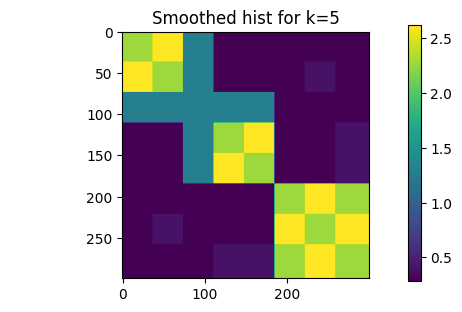

In [23]:
import matplotlib.pyplot as plt
#Comparing p_ij's
block_size = (n/(nrow_tile*np.ones(nrow_tile))).astype(int)
block_size[-1] = n- np.sum(block_size[0:-1]) #last block is the rest

#Array to store all smoothed graphon for different K
pij_smooth = np.zeros(shape=(max_k, n,n))
for k in range(max_k):
    pij_smooth[k,:,:] = np.block([[sym_KM_smooth_graphon[k,i,j]*np.ones((block_size[i], block_size[j])) 
    for j in range(len(block_size))]for i in range(len(block_size))])

#True SBM for comparison
true_block_size = (n*bandwidth*np.ones(int(1/bandwidth))).astype(int)
#only for one block so far, thus the [2,i,j]
pij_true = np.block([[graphon.graphon[i,j]*np.ones((true_block_size[i], true_block_size[j])) 
for j in range(len(true_block_size))]for i in range(len(true_block_size))])

#Plot
which_k = 5
fig = plt.figure(figsize=(6, 3.2))

ax = fig.add_subplot(111)
ax.set_title("Smoothed hist for k=%.i" % which_k)
plt.imshow(pij_smooth[which_k-1,:,:])
ax.set_aspect('equal')

cax = fig.add_axes([0.12, 0.1, 0.78, 0.8])
cax.get_xaxis().set_visible(False)
cax.get_yaxis().set_visible(False)
cax.patch.set_alpha(0)
cax.set_frame_on(False)
plt.colorbar(orientation='vertical')
plt.show()

Evaluating the performance of our method